#Тема 4. Парадоксы в теории вероятностей
Рассмотреть какой-нибудь парадокс. Смоделировать его решение в Python.

## Парадокс мальчика и девочки

Парадокс мальчика и девочки (задача о двух детях) был опубликован Мартином Гарднером в 1959 году в журнале *Scientific American*. Как и задача Монти Холла, он связан с условной вероятностью: ответ, который подсказывает интуиция, не совпадает с результатом расчёта.

## Условие задачи

В семье двое детей. Известно, что хотя бы один из них мальчик. Найти вероятность того, что оба ребёнка мальчики.

Предполагается, что рождение мальчика и девочки равновероятно, а пол одного ребёнка не зависит от пола другого.

Пусть событие $A$ - хотя бы один из детей мальчик, событие $B$ - оба ребёнка мальчики.

Обозначим мальчика буквой М, девочку буквой Д, и будем записывать сначала старшего ребёнка, потом младшего. Тогда пространство элементарных исходов:

$\Omega = \{ММ,\ МД,\ ДМ,\ ДД\}$,

причём все исходы равновероятны: $P = \dfrac{1}{2}\cdot\dfrac{1}{2} = \dfrac{1}{4}$.

Событию $A$ благоприятствуют исходы $ММ,\ МД,\ ДМ$, следовательно $P(A) = \dfrac{3}{4}$.

Событие $B$ содержится в событии $A$ (если оба мальчики, то хотя бы один точно мальчик), поэтому $AB = B = \{ММ\}$ и $P(AB) = \dfrac{1}{4}$.

По формуле условной вероятности:

$P(B|A) = \dfrac{P(AB)}{P(A)} = \dfrac{1/4}{3/4} = \dfrac{1}{3} \approx 0.333$


Вероятнее всего, человек подумает об ответе $\dfrac{1}{2}$, т.к. пол второго ребёнка не зависит от первого. Но в условии не сказано, какой именно ребёнок мальчик (старший или младший). Условие «хотя бы один мальчик» исключает только исход ДД, и из трёх оставшихся равновероятных исходов благоприятный всего один.


Смоделируем рождение детей в большом количестве семей и найдём частоту семей с двумя мальчиками среди тех, где есть хотя бы один мальчик:

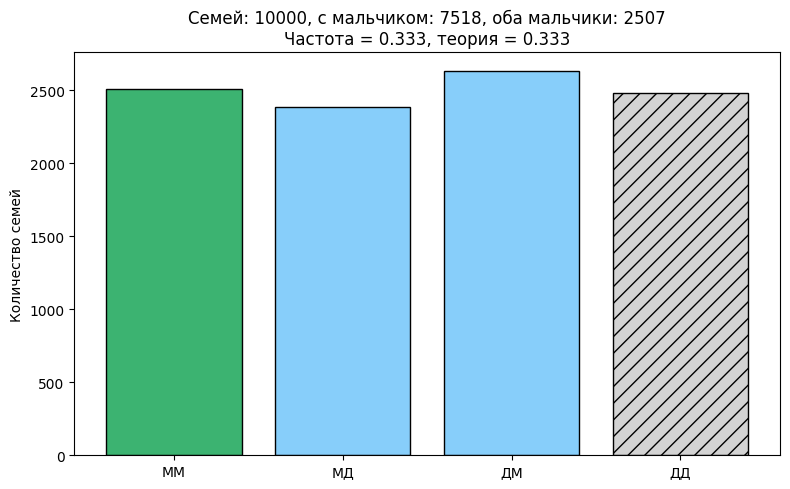

Всего семей:                      10000
Есть хотя бы один мальчик:        7518
Из них оба мальчики:              2507
Частота N_AB / N_A:               0.3335
Теоретическая вероятность P(B|A): 0.3333


In [1]:
import pandas as pd
import matplotlib.pyplot as plt


n_families = 10000

# М - мальчик, Д - девочка
sex = pd.Series(['М', 'Д'])
families = pd.Series([''.join(sex.sample(2, replace=True)) for _ in range(n_families)])

with_boy = families[families != 'ДД']    # хотя бы один мальчик
n_A = len(with_boy)
n_AB = (with_boy == 'ММ').sum()          # оба мальчики

P_theory = 1 / 3
P_sim = n_AB / n_A

# количество семей каждого вида
counts = families.value_counts().reindex(['ММ', 'МД', 'ДМ', 'ДД'])
colors = ['mediumseagreen', 'lightskyblue', 'lightskyblue', 'lightgray']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor='black')
bars[3].set_hatch('//')
ax.set_ylabel('Количество семей')
ax.set_title(f'Семей: {n_families}, с мальчиком: {n_A}, оба мальчики: {n_AB}\n'
             f'Частота = {P_sim:.3f}, теория = {P_theory:.3f}')

plt.tight_layout()
plt.show()

print(f'Всего семей:                      {n_families}')
print(f'Есть хотя бы один мальчик:        {n_A}')
print(f'Из них оба мальчики:              {n_AB}')
print(f'Частота N_AB / N_A:               {P_sim:.4f}')
print(f'Теоретическая вероятность P(B|A): {P_theory:.4f}')